<img src="https://devra.ai/analyst/notebook/1414/image.jpg" style="width: 100%; height: auto;" />

<div style="text-align:center; border-radius:15px; padding:15px; color:white; margin:0; font-family: 'Orbitron', sans-serif; background: #2E0249; background: #11001C; box-shadow: 0px 4px 8px rgba(0, 0, 0, 0.3); overflow:hidden; margin-bottom: 1em;">
  <div style="font-size:150%; color:#FEE100"><b>Ice Cream Sales Analysis and Predictor</b></div>
  <div>This notebook was created with the help of <a href="https://devra.ai/ref/kaggle" style="color:#6666FF">Devra AI</a></div>
</div>

Curiosity is the spice of life and in this notebook we explore the intriguing interplay between temperature, weather, and ice cream sales. If you find this analysis useful, please consider upvoting.

## Table of Contents

- [Introduction](#Introduction)
- [Data Loading and Inspection](#Data-Loading-and-Inspection)
- [Data Cleaning and Preprocessing](#Data-Cleaning-and-Preprocessing)
- [Exploratory Data Analysis](#Exploratory-Data-Analysis)
- [Predictive Modeling](#Predictive-Modeling)
- [Model Evaluation and Future Work](#Model-Evaluation-and-Future-Work)

## Introduction

In this notebook, we take a detailed look at a dataset that examines ice cream sales in conjunction with temperature, pricing, and tourist numbers. One might say the data is as refreshing as a scoop on a hot day. Our goal is to explore the relationships within the data and build a predictive model to estimate ice cream sales based on the available features.

In [1]:
# Suppress warnings for a cleaner notebook output
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

# Import matplotlib and set backend
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.switch_backend('Agg')

import seaborn as sns

# Ensure inline plotting if executing in a Kaggle environment
%matplotlib inline

print('Libraries imported successfully.')

Libraries imported successfully.


## Data Loading and Inspection

We begin by loading the dataset. For anyone who encounters issues during this step, the key aspects to verify include verifying the file path and checking that the delimiter and encoding in the CSV match those in the data file description.

In [3]:
# Load the dataset
file_path = 'Icecream Sales wr Rain and Temperature.csv'
df = pd.read_csv(file_path, delimiter=',', encoding='ascii')

# Display the first few rows
print('Dataset loaded successfully.')
df.head()

Dataset loaded successfully.


,Temperature (F),Ice-cream Price ($),Number of Tourists (thousands),"Ice Cream Sales ($,thousands)",Did it rain on that day?
0,80.6,1.0,89.5,90,No
1,75.2,1.0,86.4,85,No
2,86.0,2.0,99.2,107,No
3,75.2,2.0,72.4,71,Yes
4,60.8,2.0,71.2,65,Yes


## Data Cleaning and Preprocessing

In this section, we inspect the dataset for any cleaning requirements. The dataset contains the following fields:
- Temperature (F) [number]
- Ice-cream Price ($) [number]
- Number of Tourists (thousands) [number]
- Ice Cream Sales ($,thousands) [integer]
- Did it rain on that day? [string]

Since the dataset is relatively clean, our primary focus will be on converting the categorical rain column into a numeric format that can be included in our predictive model.

In [ ]:
# Check for missing values and basic information
print('Dataframe info:')
df.info()

# Optionally, check for null values
print('Missing values in each column:')
print(df.isnull().sum())

# Convert the categorical column 'Did it rain on that day?' to a binary numeric column
df['Rain'] = df['Did it rain on that day?'].str.strip().str.lower().map({'yes': 1, 'no': 0})

# If any errors occur during mapping, it's useful to check the unique values in the column
if df['Rain'].isnull().any():
    print('Warning: Some entries in "Did it rain on that day?" could not be mapped. Unique values:', df['Did it rain on that day?'].unique())

# Drop the original rain column if the new one is created
df.drop(columns=['Did it rain on that day?'], inplace=True)

print('Data cleaning complete.')
df.head()

Dataframe info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Temperature (F)                 20 non-null     float64
 1   Ice-cream Price ($)             20 non-null     float64
 2   Number of Tourists (thousands)  20 non-null     float64
 3   Ice Cream Sales ($,thousands)   20 non-null     int64  
 4   Did it rain on that day?        20 non-null     object 
dtypes: float64(3), int64(1), object(1)
memory usage: 928.0+ bytes
Missing values in each column:
Temperature (F)                   0
Ice-cream Price ($)               0
Number of Tourists (thousands)    0
Ice Cream Sales ($,thousands)     0
Did it rain on that day?          0
dtype: int64
Data cleaning complete.


,Temperature (F),Ice-cream Price ($),Number of Tourists (thousands),"Ice Cream Sales ($,thousands)",Rain
0,80.6,1.0,89.5,90,0
1,75.2,1.0,86.4,85,0
2,86.0,2.0,99.2,107,0
3,75.2,2.0,72.4,71,1
4,60.8,2.0,71.2,65,1


## Exploratory Data Analysis

Below we dive into descriptive statistics and visualizations for the dataset. We'll employ a variety of plotting methods to reveal insights and relationships between variables. The plots include histograms, bar charts, box plots, violin plots, pair plots, and a correlation heatmap for numeric variables. If anything seems off, remember: data cleaning is both an art and a science.

Descriptive statistics:
       Temperature (F)  Ice-cream Price ($)  Number of Tourists (thousands)  \
count        20.000000            20.000000                       20.000000   
mean         73.130000             1.362500                       78.955000   
std           7.598137             0.496534                       10.992556   
min          60.800000             0.750000                       52.100000   
25%          67.550000             1.000000                       71.175000   
50%          75.200000             1.375000                       76.600000   
75%          78.800000             2.000000                       88.025000   
max          86.000000             2.000000                       99.200000   

       Ice Cream Sales ($,thousands)       Rain  
count                      20.000000  20.000000  
mean                       76.850000   0.700000  
std                        13.259654   0.470162  
min                        53.000000   0.000000  
25%           

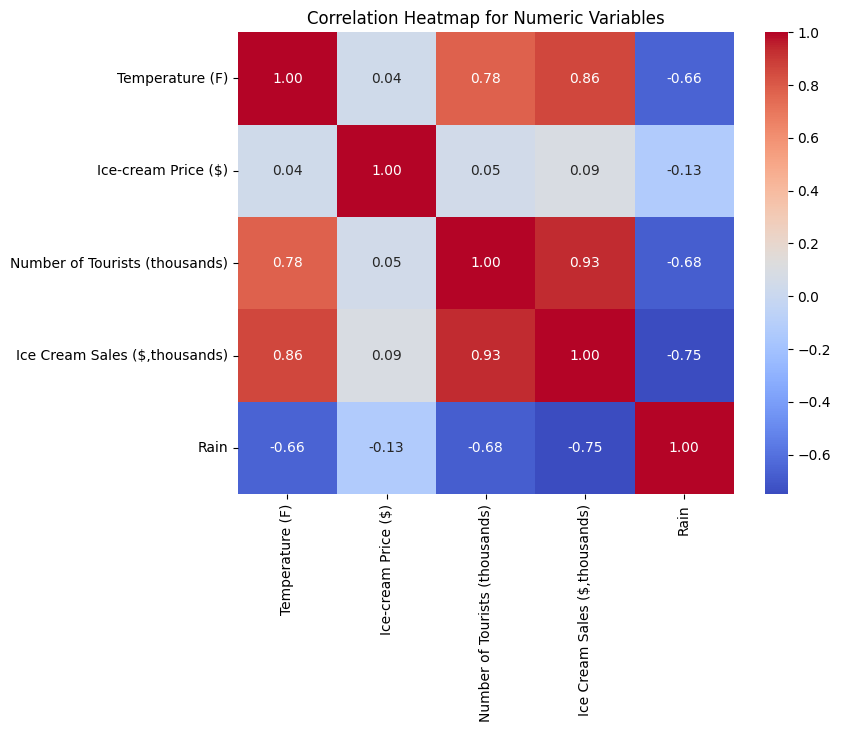

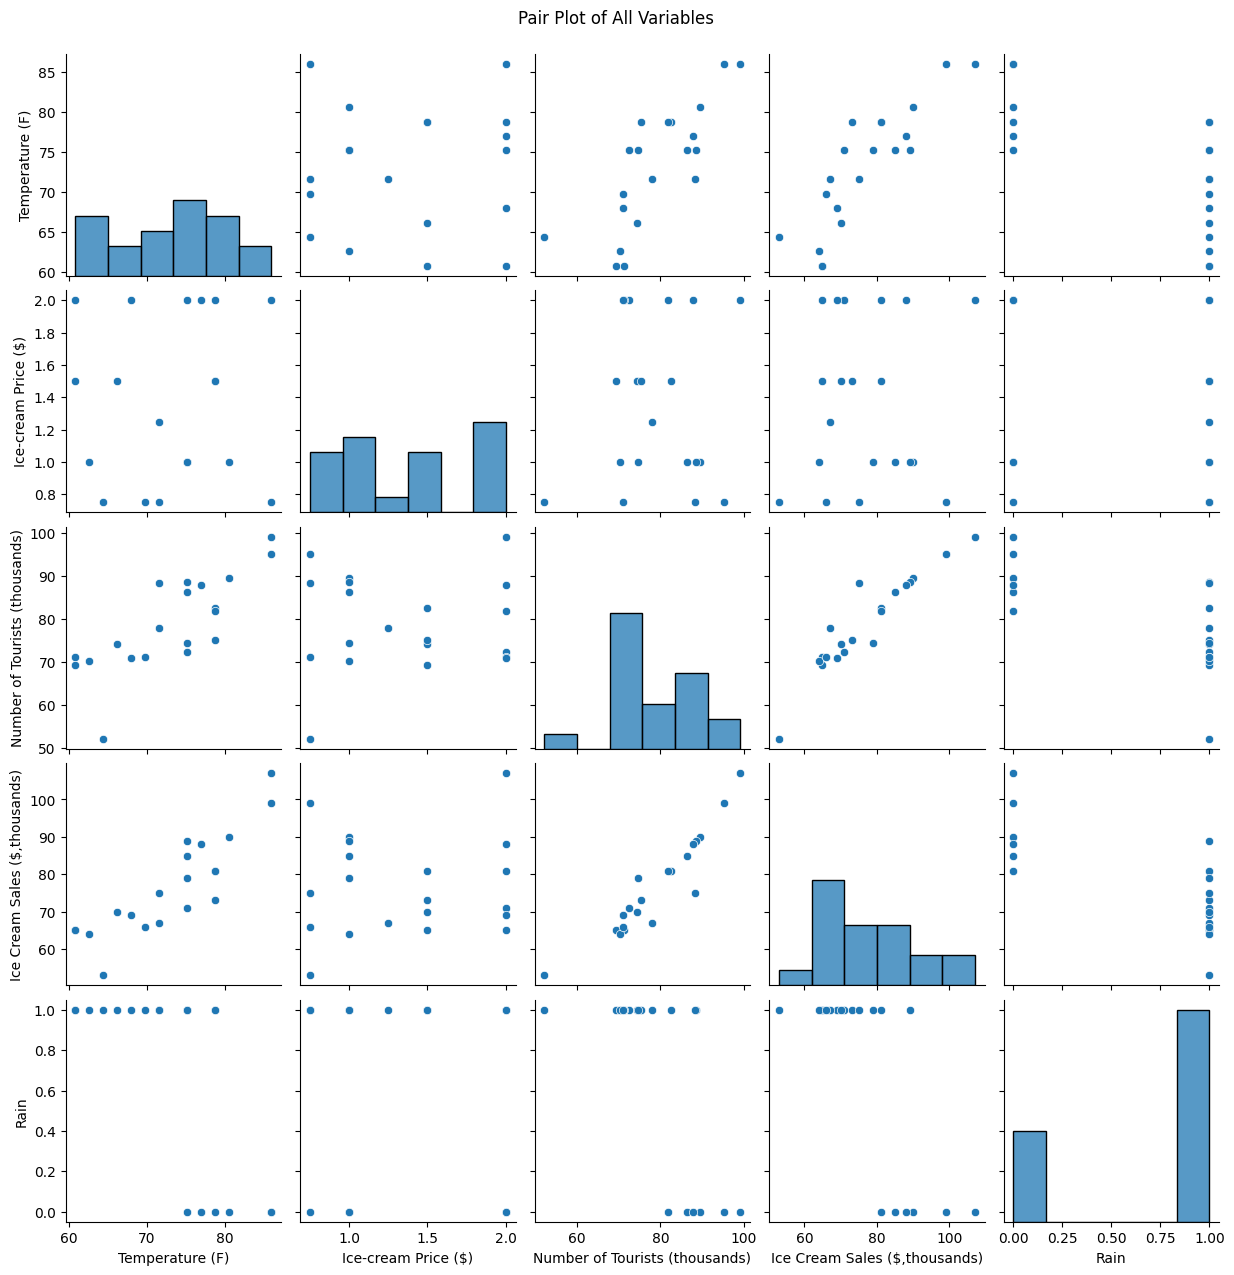

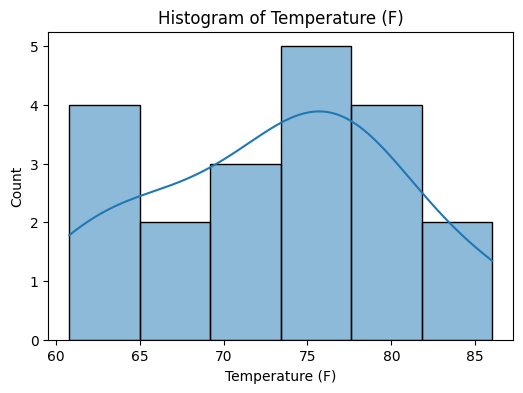

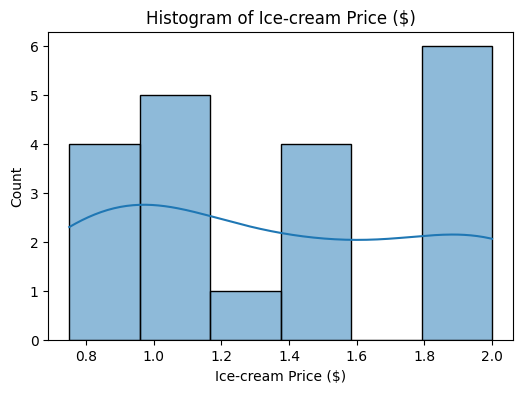

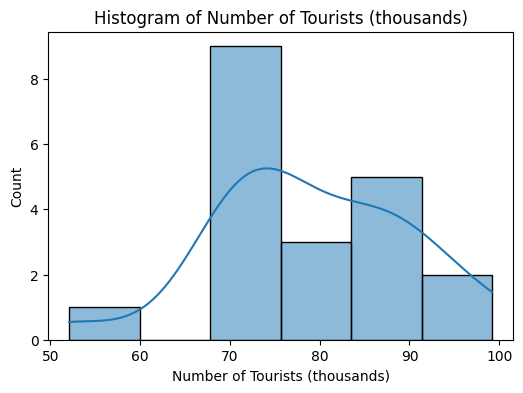

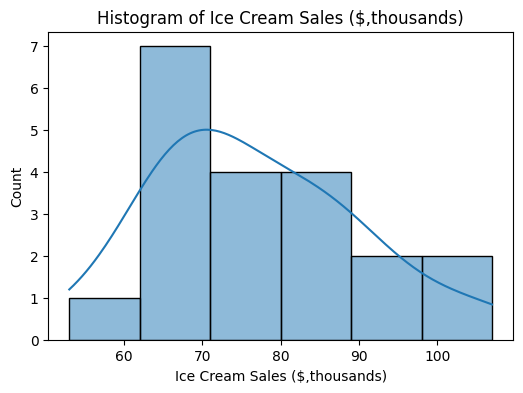

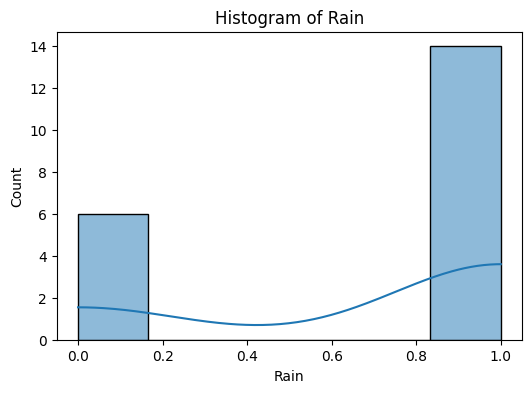

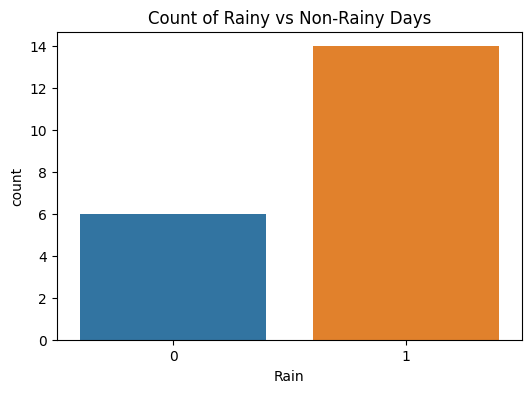

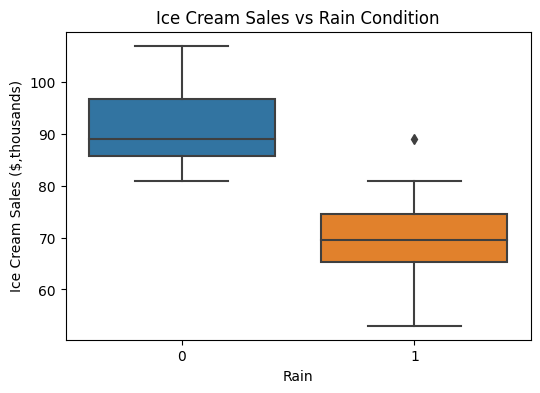

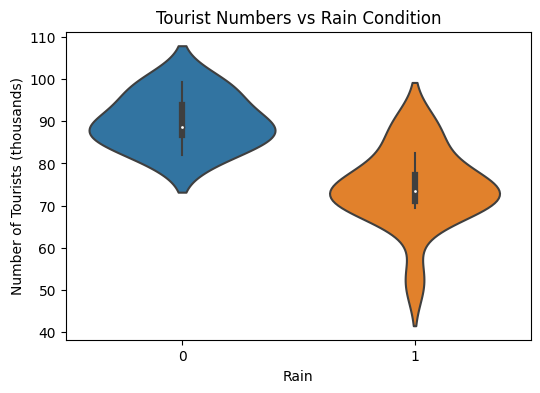

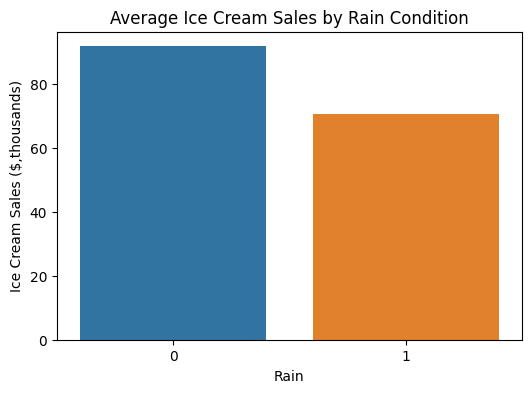

In [ ]:
# Descriptive statistics
print('Descriptive statistics:')
print(df.describe())

# List of numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# 1. Correlation Heatmap (only if there are four or more numeric columns)
if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(8, 6))
    corr = numeric_df.corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap for Numeric Variables')
    plt.show()

# 2. Pair Plot
sns.pairplot(df, diag_kind='hist')
plt.suptitle('Pair Plot of All Variables', y=1.02)
plt.show()

# 3. Histograms for numeric columns
numeric_columns = numeric_df.columns
for col in numeric_columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.show()

# 4. Count Plot for the Rain indicator
plt.figure(figsize=(6, 4))
sns.countplot(x='Rain', data=df)
plt.title('Count of Rainy vs Non-Rainy Days')
plt.show()

# 5. Box Plot for Ice Cream Sales vs Temperature
plt.figure(figsize=(6, 4))
sns.boxplot(x='Rain', y='Ice Cream Sales ($,thousands)', data=df)
plt.title('Ice Cream Sales vs Rain Condition')
plt.show()

# 6. Violin Plot for Number of Tourists vs Temperature
plt.figure(figsize=(6, 4))
sns.violinplot(x='Rain', y='Number of Tourists (thousands)', data=df)
plt.title('Tourist Numbers vs Rain Condition')
plt.show()

# 7. Grouped Barplot for Average Ice Cream Sales by Rain
plt.figure(figsize=(6, 4))
sns.barplot(x='Rain', y='Ice Cream Sales ($,thousands)', data=df, ci=None)
plt.title('Average Ice Cream Sales by Rain Condition')
plt.show()

## Predictive Modeling

Given the available features, we can create a linear regression model to predict ice cream sales. Our features include temperature, price, number of tourists, and the binary indicator for rain. Note that predicting sales based on these inputs may yield interesting insights, although the nature of the data always leaves room for unpredictable cravings.

We split the dataset into training and testing subsets and assess our model using the coefficient of determination (R² score).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Define the predictor variables and the target variable
features = ['Temperature (F)', 'Ice-cream Price ($)', 'Number of Tourists (thousands)', 'Rain']
target = 'Ice Cream Sales ($,thousands)'

X = df[features]
y = df[target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions and evaluate the model
y_pred = model.predict(X_test)
score = r2_score(y_test, y_pred)

print(f'Linear Regression R^2 Score: {score:.2f}')

Linear Regression R^2 Score: 0.97


## Model Evaluation and Future Work

Our linear regression model provides an R² score that indicates the proportion of variance in ice cream sales explained by our features. While the R² score is a useful benchmark, there is always room for improvement. Future analysis might include:

- Trying other regression models such as Ridge, Lasso, or ensemble methods
- Performing cross-validation to optimize model parameters
- Analyzing residuals for patterns or heteroscedasticity
- Incorporating additional data sources like holiday indicators or more detailed weather data

We hope this notebook provides a solid foundation for exploring and modeling the factors that influence ice cream sales. If you have any suggestions or find this analysis engaging, please give it an upvote.

## Conclusion

In this notebook, we performed a comprehensive analysis of ice cream sales in relation to temperature, pricing, tourism, and weather conditions. We not only visualized key relationships in the data but also developed a linear regression model to predict sales. The insights gained here serve as a starting point for more advanced investigations into consumer behavior and sales optimization.

Thank you for reviewing this notebook.